In [2]:
import os
import h5py
import matplotlib.pyplot as plt
import numpy as np

# Configuración visual por defecto para el TFG (opcional)
plt.style.use('seaborn-v0_8-whitegrid')

ruta = os.path.join("data", "Galaxy10_DECals.h5")

with h5py.File(ruta, "r") as f:
  print("Claves disponibles:", list(f.keys()))

  images = f["images"]
  labels = f["ans"]

  n_samples = images.shape[0]
  shape_img = images.shape[1:]
  clases_encontradas = np.unique(labels[:])

  print(f"Total de imágenes: {n_samples}")
  print(f"Dimensiones de cada imagen: {shape_img}")
  print(f"Número de clases únicas: {len(clases_encontradas)}")
  print(f"Clases: {clases_encontradas}")

Claves disponibles: ['ans', 'dec', 'images', 'pxscale', 'ra', 'redshift']
Total de imágenes: 17736
Dimensiones de cada imagen: (256, 256, 3)
Número de clases únicas: 10
Clases: [0 1 2 3 4 5 6 7 8 9]


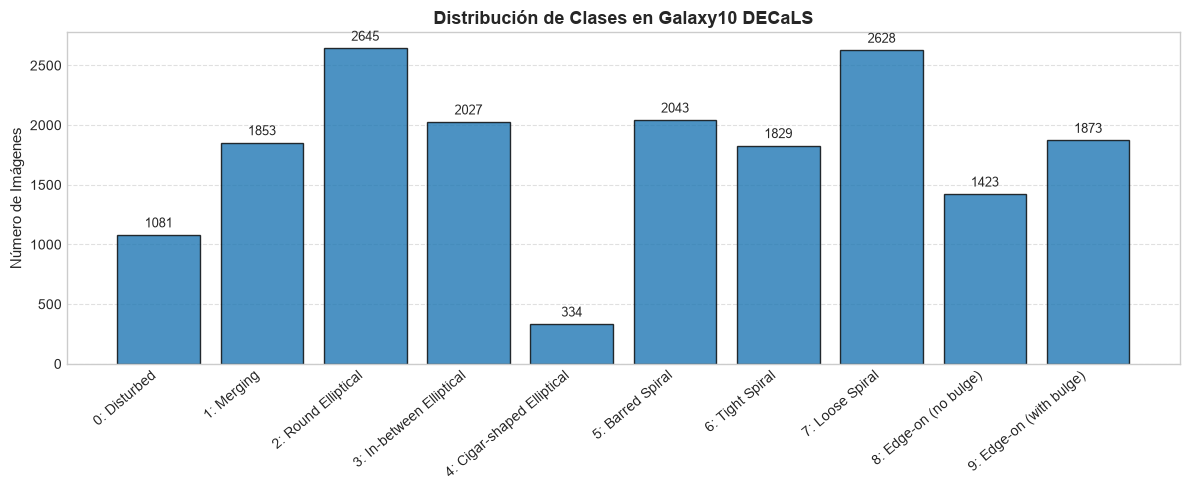

In [7]:
# 1. Cargar etiquetas y metadatos
with h5py.File("data/Galaxy10_DECals.h5", "r") as f:
  labels = np.array(f["ans"])
  redshift = np.array(f["redshift"])

# Nombres oficiales de las 10 clases en Galaxy10 DECaLS
class_names = [
    "0: Disturbed",
    "1: Merging",
    "2: Round Elliptical",
    "3: In-between Elliptical",
    "4: Cigar-shaped Elliptical",
    "5: Barred Spiral",
    "6: Tight Spiral",
    "7: Loose Spiral",
    "8: Edge-on (no bulge)",
    "9: Edge-on (with bulge)",
]

# 2. Conteo de frecuencias
unique_classes, counts = np.unique(labels, return_counts=True)

# 3. Gráfico de barras del desbalance
plt.figure(figsize=(12, 5))
bars = plt.bar(
    [class_names[i] for i in unique_classes],
    counts,
    color="#1f77b4",
    edgecolor="black",
    alpha=0.8,
)
plt.xticks(rotation=40, ha="right", fontsize=10)
plt.ylabel("Número de Imágenes", fontsize=11)
plt.title("Distribución de Clases en Galaxy10 DECaLS", fontsize=13, weight="bold")
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.grid(axis="x", visible=False)

# Añadir el número exacto sobre cada barra
for bar in bars:
  yval = bar.get_height()
  plt.text(
      bar.get_x() + bar.get_width() / 2,
      yval + 40,
      f"{yval}",
      ha="center",
      va="bottom",
      fontsize=9,
  )

plt.tight_layout()
plt.show()

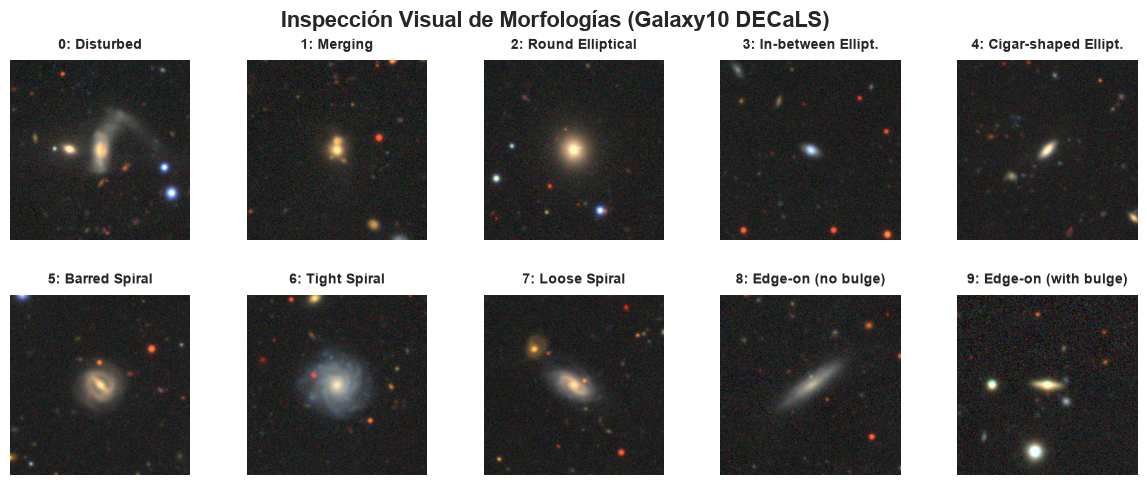

In [6]:
import h5py
import matplotlib.pyplot as plt
import numpy as np

# 1. Nombres oficiales (abreviados si es necesario para mayor claridad)
class_names = [
    "0: Disturbed",
    "1: Merging",
    "2: Round Elliptical",
    "3: In-between Ellipt.",
    "4: Cigar-shaped Ellipt.",
    "5: Barred Spiral",
    "6: Tight Spiral",
    "7: Loose Spiral",
    "8: Edge-on (no bulge)",
    "9: Edge-on (with bulge)",
]

# 2. Cargar una muestra visual por cada morfología
with h5py.File("data/Galaxy10_DECals.h5", "r") as f:
    images = f["images"]
    labels = np.array(f["ans"])
    
    # Crear la figura asegurando espacio suficiente (figsize más alto)
    fig, axes = plt.subplots(2, 5, figsize=(15, 5))

    for class_id, ax in enumerate(axes.flat):
        # Buscar el índice de la primera imagen de esta clase
        idx = np.where(labels == class_id)[0][0]
        img = images[idx]

        ax.imshow(img)
        # Reducir tamaño de fuente y añadir un 'pad' para separar del cuadro
        ax.set_title(class_names[class_id], fontsize=10, weight="bold", pad=8)
        ax.axis("off")

# 3. Ajuste fino de los espaciados
plt.suptitle(
    "Inspección Visual de Morfologías (Galaxy10 DECaLS)",
    fontsize=16,
    weight="bold",
    y=0.98 # Subir el título principal
)

# hspace = espacio vertical entre filas, wspace = espacio horizontal
plt.subplots_adjust(hspace=0.3, wspace=0.1, top=0.88, bottom=0.05)
plt.show()

In [8]:
import torch

print(f"Versión PyTorch: {torch.__version__}")
print(f"¿CUDA disponible?: {torch.cuda.is_available()}")
if torch.cuda.is_available():
  print(f"Dispositivo activo: {torch.cuda.get_device_name(0)}")

Versión PyTorch: 2.5.1+cu121
¿CUDA disponible?: True
Dispositivo activo: NVIDIA GeForce RTX 4060 Laptop GPU


In [9]:
import os
import h5py
import numpy as np
from sklearn.model_selection import train_test_split
import torch
from torch.utils.data import DataLoader, Dataset
from transformers import AutoImageProcessor

# 1. Cargar etiquetas e índices desde el archivo local .h5
ruta_h5 = os.path.join("data", "Galaxy10_DECals.h5")
with h5py.File(ruta_h5, "r") as f:
  total_muestras = f["ans"].shape[0]
  etiquetas = np.array(f["ans"])

indices = np.arange(total_muestras)

# 2. División estratificada (70% train, 15% val, 15% test)
train_idx, temp_idx, y_train, y_temp = train_test_split(
    indices, etiquetas, test_size=0.30, stratify=etiquetas, random_state=42
)
val_idx, test_idx, y_val, y_test = train_test_split(
    temp_idx, y_temp, test_size=0.50, stratify=y_temp, random_state=42
)

print(
    f"Partición completada -> Train: {len(train_idx)} | Val: {len(val_idx)} |"
    f" Test: {len(test_idx)}"
)


# 3. Dataset personalizado para leer por lotes directamente del disco HDF5
class Galaxy10Dataset(Dataset):

  def __init__(self, h5_path, indices, processor):
    self.h5_path = h5_path
    self.indices = indices
    self.processor = processor
    self.file = None

  def __len__(self):
    return len(self.indices)

  def __getitem__(self, idx):
    if self.file is None:
      self.file = h5py.File(self.h5_path, "r")

    real_idx = self.indices[idx]
    image = self.file["images"][real_idx]  # (256, 256, 3)
    label = int(self.file["ans"][real_idx])

    # Preprocesamiento oficial de DINOv2 (reescalado a 224x224 y normalización)
    encoding = self.processor(
        images=image, return_tensors="pt"
    )  # Devuelve pixel_values: (1, 3, 224, 224)
    pixel_values = encoding["pixel_values"].squeeze(
        0
    )  # Dejar en (3, 224, 224)

    return {
        "pixel_values": pixel_values,
        "labels": torch.tensor(label, dtype=torch.long),
    }


# 4. Inicializar procesador y DataLoader para el conjunto de test
model_id = "facebook/dinov2-base"
processor = AutoImageProcessor.from_pretrained(model_id)

test_dataset = Galaxy10Dataset(ruta_h5, test_idx, processor)
test_loader = DataLoader(
    test_dataset, batch_size=32, shuffle=False, num_workers=0
)

Partición completada -> Train: 12415 | Val: 2660 | Test: 2661


In [11]:
from codecarbon import EmissionsTracker
import torch
from transformers import AutoModelForImageClassification

# 1. Configurar dispositivo GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Ejecutando inferencia en: {torch.cuda.get_device_name(0)}")

# 2. Cargar DINOv2 adaptado a 10 clases
model = AutoModelForImageClassification.from_pretrained(
    model_id, num_labels=10, ignore_mismatched_sizes=True
).to(device)
model.eval()

# 3. Inicializar auditoría energética con CodeCarbon
tracker = EmissionsTracker(
    project_name="Galaxy10_DINOv2_Baseline_Test",
    output_dir="data",
    save_to_file=True,
    log_level="warning",
)

# 4. Ejecución del primer lote de prueba (32 galaxias)
batch = next(iter(test_loader))
pixel_values = batch["pixel_values"].to(device)
labels = batch["labels"].to(device)

tracker.start()
with torch.no_grad():
  outputs = model(pixel_values=pixel_values)
  predicciones = torch.argmax(outputs.logits, dim=-1)
emisiones_kg = tracker.stop()

# 5. Métricas de salida
energia_kwh = tracker.final_emissions_data.energy_consumed
print("\n--- Auditoría de Inferencia Completada ---")
print(f"Lote procesado: {len(labels)} imágenes simultáneas en GPU")
print(f"Consumo eléctrico registrado: {energia_kwh * 1000:.6f} Wh")
print(f"Emisiones de carbono: {emisiones_kg * 1e6:.4f} mg CO2eq")

Ejecutando inferencia en: NVIDIA GeForce RTX 4060 Laptop GPU


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

[transformers] Dinov2ForImageClassification LOAD REPORT from: facebook/dinov2-base
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[codecarbon WARNING @ 11:08:05] Multiple instances of codecarbon are allowed to run at the same time.
[codecarbon WARNING @ 11:08:34] Unable to access geographical location through primary API. Will resort to using the backup API - Exception : Region is empty - url=https://get.geojs.io/v1/ip/geo.json



--- Auditoría de Inferencia Completada ---
Lote procesado: 32 imágenes simultáneas en GPU
Consumo eléctrico registrado: 0.000024 Wh
Emisiones de carbono: 0.0042 mg CO2eq
